## Bancos Isolados

O problema mais simples é o de um único banco de capacitores isolado. Uma vez que o curto-circuito em MVA é geralmente conhecido para qualquer localização em um sistema, a seguinte expressão simplificada para a corrente de partida máxima é apresentada:

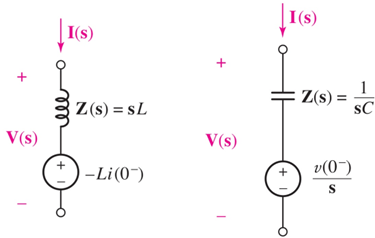

In [3]:
import sympy as sp
sp.init_printing()
import numpy as np
import matplotlib.pyplot as plt

In [12]:
t = sp.symbols("t", positive=True, real=True)
s = sp.symbols("s")
# R1, L1, C1 = sp.symbols("R_1 L_1 C_1")

In [13]:
Z1 = R1 + s*L1 + 1/(s*C1)
Z1

In [14]:
L1 = 350e-6
C1 = 50.14e-6
R1 = 0.1
Vp = 19919
w = 2*np.pi*60

In [19]:
Z1 = R1 + s*L1 + 1/(s*C1)
Z1

In [20]:
equacao = sp.Eq(Z1, 0)

In [21]:
sp.solve(Z1, s)

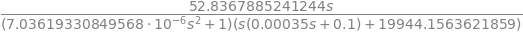

In [ ]:
V = sp.laplace_transform(Vp*sp.sin(w*t), t, s, noconds=True)
I0 = sp.simplify(V / Z0)
I0

In [ ]:
i0 = sp.inverse_laplace_transform(I0, s, t)
i0

In [ ]:
i0_num = sp.lambdify((t), i0)

In [ ]:
t_num = np.linspace(0, 5/60, 60*128)

Text(0.5, 1.0, 'Inrsuh banco isolado, $C=50.14e-6$F, $L=350e-6$H, $R = 0.1 \\Omega$ ')

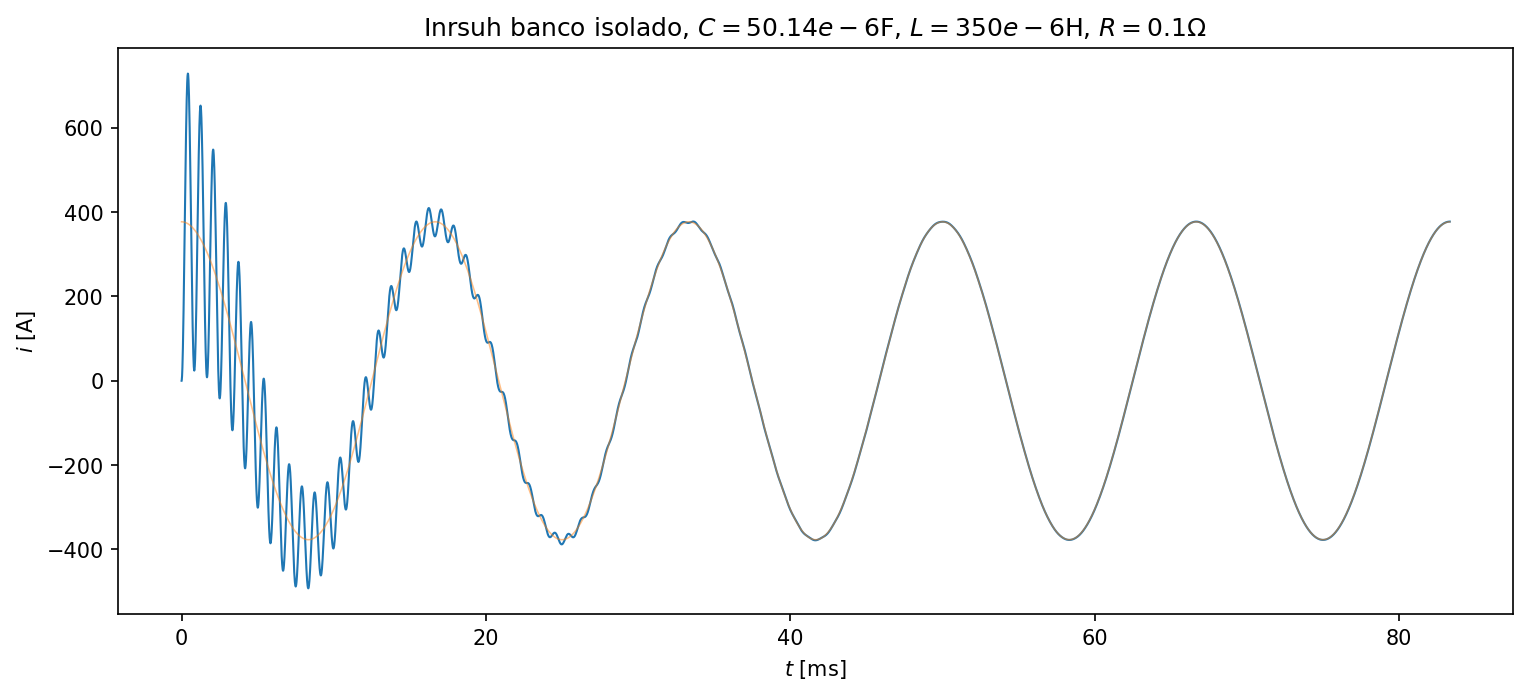

In [ ]:
fig, ax = plt.subplots(figsize=(12 ,5), dpi=150)
ax.plot(1e3*t_num, np.real(i0_num(t_num)), lw=1.0)
ax.plot(1e3*t_num, 377*np.sin(w*t_num+np.pi/2),  lw=0.75, alpha=0.5)
ax.set_xlabel('$t$ [ms]')
ax.set_ylabel('$i$ [A]')
ax.set_title('Inrsuh banco isolado, $C=50.14e-6$F, $L=350e-6$H, $R = 0.1 \\Omega$ ')

In [ ]:
i0_num = sp.lambdify((t, w, Vp, C0, L0, R0), i0)

SyntaxError: ignored

In [ ]:
t_num = np.linspace(0, 10/60, 60*128)
w_num = 2*np.pi*60
Vp_num = 


Quando um banco de capacitores é conectado em paralelo com outro banco uma corrente de *inrush* adicional fluirá, devido à descarga dos capacitores dos bancos já energizados para o banco descarregado. 

Enquanto a corrente de partida do sistema é limitada pela reatância indutiva do banco para a fonte, a corrente de partida dos bancos paralelos depende apenas da reatância indutiva entre os estágios do capacitor e da tensão no momento do fechamento da chave.

**É sempre assumido que o degrau recém-energizado é fechado em um pico de tensão do sistema e tensão zero no banco sendo energizado.** Neste instante, os estágios do capacitor já energizados têm a carga máxima sobre eles, o que resultará na maior magnitude da corrente de energização.

No pico de tensão, a corrente será igual ou próxima de zero e se a frequência do transiente for pelo menos 10 vezes maior que a da tensão de alimentação, quase toda a corrente de *inrush* para o banco recém-energizado virá dos bancos paralelos carregados.

A experiência de campo indica que a corrente de *inrush* para bancos multiestágio é geralmente entre 20 e 250 vezes o capacitor de estado estacionário.

A corrente transitória geralmente decai para algum valor insignificante em menos de um ciclo com base na frequência do sistema e geralmente terá decaído para um valor baixo em meio ciclo.


In [ ]:
R0, R1, R2, R3, R4, R5, R6= sp.symbols("R_0 R_1 R_2 R_3 R_4 R_5 R_6", positive=True, complex=True)
L0, L1, L2, L3, L4, L5, L6= sp.symbols("L_0 L_1 L_2 L_3 L_4 L_5 L_6", positive=True, complex=True)
C0, C1, C2, C3, C4, C5, C6= sp.symbols("C_0 C_1 C_2 C_3 C_4 C_5 C_6", positive=True, complex=True)
Q0, Q1, Q2, Q3, Q4, Q5, Q6= sp.symbols("Q_0 Q_1 Q_2 Q_3 Q_4 Q_5 Q_6", positive=True, complex=True)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
# from engineering_notation import EngNumber
import sympy as sp

In [ ]:
Qcap = np.array([Q1, 12e6, 12e6, 12e6, 12e6, 12e6])
comp_cabo = np.array([20.0, 20.0, 20.0, 20.0, 20.0, 20.0])
comp_barra = np.array([30.0, 30.0, 30.0, 30.0, 30.0, 30.0])
indut_distribuida_cabo = np.array([0.396, 0.396, 0.396, 0.396, 0.396, 0.396])
indut_distribuida_cabo = indut_distribuida_cabo * 1e-6
indut_distribuida_barra = np.array([0.0329, 0.0329, 0.0329, 0.0329, 0.0329, 0.0329])
indut_distribuida_barra = 1e-6 * indut_distribuida_barra
Lcap = np.array([5.0, 5.0, 5.0, 5.0, 5.0, 5.0])
Lcap = 1e-6 * Lcap
Lreator = np.array([200.0, 200.0, 200.0, 200.0, 200.0, 200.0])
Lreator = 1e-6 * Lreator

Vff = 23.0e3
freq = 60

In [ ]:
Lcabo = comp_cabo * indut_distribuida_cabo
Lbarra = comp_barra * indut_distribuida_barra
Ltotal_sem_reator = Lbarra + Lcabo  + Lcap

In [ ]:
R0, R1, R2, R3, R4, R5, R6= sp.symbols("R_0 R_1 R_2 R_3 R_4 R_5 R_6")
L0, L1, L2, L3, L4, L5, L6= sp.symbols("L_0 L_1 L_2 L_3 L_4 L_5 L_6")
Q0, Q1, Q2, Q3, Q4, Q5, Q6= sp.symboQs("Q_0 Q_1 Q_2 Q_3 Q_4 Q_5 Q_6")
Lcc = 





In [ ]:
Yeq = 1/Z1 + 1/Z2 + 1/Z3 + 1/Z4 + 1/Z5 + 1/Z6
Zeq = Z0 + 1/Yeq
Zeq

In [ ]:
Qcap = np.array([12e6, 12e6, 12e6, 12e6, 12e6, 12e6])
comp_cabo = np.array([20.0, 20.0, 20.0, 20.0, 20.0, 20.0])
comp_barra = np.array([30.0, 30.0, 30.0, 30.0, 30.0, 30.0])
indut_distribuida_cabo = np.array([0.396, 0.396, 0.396, 0.396, 0.396, 0.396])
indut_distribuida_cabo = indut_distribuida_cabo * 1e-6
indut_distribuida_barra = np.array([0.0329, 0.0329, 0.0329, 0.0329, 0.0329, 0.0329])
indut_distribuida_barra = 1e-6 * indut_distribuida_barra
Lcap = np.array([5.0, 5.0, 5.0, 5.0, 5.0, 5.0])
Lcap = 1e-6 * Lcap
Lreator = np.array([200.0, 200.0, 200.0, 200.0, 200.0, 200.0])
Lreator = 1e-6 * Lreator

Vff = 23.0e3
freq = 60

# Cálculo da Corrente Transitória de Energização

## Bancos de Capacitores - "Back to Back".

### Dados Nominais do Banco a ser energizado

In [1]:
ww = 2 * np.pi * freq
Vfn = Vff/np.sqrt(3)
Xcap = Vff**2 / Qcap
Ccap = 1 / ( ww * Xcap )
Ifn_cap = Vfn / Xcap

NameError: ignored

In [ ]:
for kk in range(len(Ccap)):
    print('C [',kk,'] = ', EngNumber(Ccap[kk]),'F')

In [ ]:
Lcabo = comp_cabo * indut_distribuida_cabo
Lbarra = comp_barra * indut_distribuida_barra
Ltotal_sem_reator = Lbarra + Lcabo  + Lcap

In [ ]:
for kk in range(len(Ltotal_sem_reator)):
    print('L [',kk,'] = ', EngNumber(Ltotal_com_reator[kk]),'H')

In [ ]:
den_C =  1/Ccap[0] + 1/np.sum(Ccap[1:])
Cequiv = 1 / den_C
den_L =  np.sum(1/Ltotal_sem_reator[1:])
Lequiv = Ltotal_sem_reator[0] + 1 / den_L 
print(EngNumber(Cequiv),'F')
print(EngNumber(Lequiv),'H')

In [ ]:
1/den_L

In [ ]:
Ltotal_sem_reator